# Homework 11: Schrödinger equation as an eigenvalue problem

**Course title:** Computer Simulation Methods in Physics (Phys 4071/5071; Fall 2025)  
**This homework assignment is due December 5, 2025, at 6 pm.** Note the **extended submission deadline**.   
(Submission via the shared `GitHub` repository.)

**Before you submit your homework, make sure that you click `Kernel > Restart & Run All`**.

Quantum mechanics can often be formulated as matrix problems and solved on a computer using linear algebra methods. Suppose, for example, a one-dimensional quantum well of width $L$, but not a square well like the ones you commonly find discussed in textbooks. Suppose instead that the potential $V(x)$ varies inside the well.
We cannot solve such problems analytically in general, but we can solve them on the computer.

Let us consider an electron with mass $M = 9.1094 \cdot 10^{-31}\,{\rm kg}$ and charge of $1.6022\cdot 10^{-19} {\rm C}$ in a potential, which has infinite walls at $x=0$ and $x=L$: 

$$
V(x) = 
\begin{cases}
V_0 \cosh \left[\left ( {x \over L} - {1 \over 2}\right )^2 \right] & \text{for}~ 0<x<L \\
\infty  & \text{otherwise,}
\end{cases}
$$

with $V_0 = 10 \, {\rm eV}$ and a width of $L = 1 \,{\rm nm}$. The **energy eigenvalues** $E$ and the corresponding **eigenfunctions** $\psi(x)$ of the system are determined by the (one-dimensional) Schrödinger equation

$$
\hat{H}\psi(x) = E\psi(x) \,,
$$

with the Hamiltonian 

$$
\hat{H} = \hat{T} + V(x) = -\frac{\hbar^2}{2M} \frac{d^2}{dx^2} + V(x)
$$ 

and the **boundary conditions** $\psi(x=0)=\psi(x=L)\equiv 0$ due to the infinite walls.

To solve the Schrödinger equation with these boundary conditions, we make the following **ansatz**:

$$
\psi(x) = \sum_{n=1}^N c_n \sin \left ( {n\pi x \over L} \right ) \,,
$$

with to-be-determined coefficients $\lbrace{c_n} \rbrace_n$ and then express it as the matrix eigenvalue problem

$$
\begin{pmatrix}
H_{11} & H_{12} & \ldots & H_{1N}\\
H_{21} & H_{22} & \ldots & H_{2N}\\
\vdots & \vdots & \ddots & \vdots \\
H_{N1} & H_{N2} & \ldots & H_{NN}
\end{pmatrix}
\begin{pmatrix}
c_1\\ c_2 \\ \vdots \\ c_N
\end{pmatrix}
= 
E
\begin{pmatrix}
c_1\\ c_2 \\ \vdots \\ c_N
\end{pmatrix} \,.
$$

For the matrix elements of the Hamiltonian in this basis, $H_{nm} \equiv T_{nm} + V_{nm}$, one finds

\begin{align}
T_{nm} &= {1 \over 2}{\pi^2 \hbar^2 m^2 \over M L^2}\delta_{nm} \equiv n^2 \, \bar{E} \, \delta_{nm} \,,\\
V_{nm} &= {2V_0 \over L}\int_{0}^L dx \sin{n\pi x \over L} V(x)\sin{m\pi x \over L} \\
&= 2V_0 \int_{0}^1 ds \sin(n\pi s) \cosh \left[ \left ( s - {1 \over 2}\right )^2 \right] \sin(m\pi s) \,,
\end{align}

with $s = x/L$ and $\bar{E} \approx 0.3760 \, {\rm eV}$. Note that the integral in the definition of $V_{nm}$ has to be evaluated numerically.

The Hamiltonian matrix $H$ with elements $H_{nm}$ is, in theory, infinitely large, so we cannot calculate all its eigenvalues. But we can get a pretty accurate solution for the first few of them by cutting off the matrix after the first few elements.

(a) Show analytically that the Schrödinger equation for this problem can indeed be written as a matrix eigenvalue problem and derive the expressions given for $T_{nm}$ and $V_{nm}$. You may use the identity:
$$
\int_{0}^L \sin{n\pi x \over L}\sin{m\pi x \over L}dx = {L \over 2}\delta_{nm} \,.
$$

## Homework 11 — Part (a)

We expand an arbitrary wave function as a starting point (bras and kets are defined by the  $\sin(\frac{n \pi x}{L})$ bases (n and m are interchangeable)

$$
\Psi(x) = \sum_{n=1}^{N} C_n \sin\left(\frac{n\pi x}{L}\right)
        = \sum_{n=1}^{N} C_n \lvert \phi_n \rangle.
$$

The time-independent Schrodinger equation becomes

$$
\hat{H}\sum_{n=1}^{N} C_n \lvert \phi_n \rangle
= E \sum_{n=1}^{N} C_n \lvert \phi_n \rangle.
$$

Applying the projection operator to both sides$\sum_{m = 1}^{M} C_{m} \rvert \phi_m \rangle\langle \phi_m\rvert C_{m}^{*}$:

Another useful identity: $C_{m}^{*} \times C_{n} = |C|^{2}$

Using orthonormality $\langle \phi_m \vert \phi_n \rangle = \delta_{mn} \frac{L}{2}$:

$$
\sum_{n=1}^{N} \sum_{m=1}^{M} C_{m} \rvert \phi_m \rangle \langle\phi_m \rvert \hat{H} \rvert \phi_m \rangle |C|^{2} = |C|^{2} E \sum_{n=1}^{N} \sum_{m=1}^{M}  C_{m} \langle \phi_m \rvert \phi_m \rangle  
$$
$ |C|^{2}$ terms cancel on both sides, left side $\langle\phi_m \rvert \hat{H} \rvert \phi_m \rangle$ becomes matrix element $H_{mn}$, and orthonormality condition: $\langle \phi_m \vert \phi_n \rangle = \delta_{mn} \frac{L}{2}$ will be applied to right sided equation.

$$
\sum_{n=1}^{N} \sum_{m=1}^{M} H_{mn} C_{m}   =  E \sum_{n=1}^{N} \sum_{m=1}^{M} C_{m}  \delta_{mn} \frac{L}{2}
$$

The right-hand side of the equation will eliminate the n-summation using the Kronecker delta properties.

$$
\sum_{n=1}^{N} \sum_{m=1}^{M} H_{mn} C_{m}  =  E \sum_{m=1}^{M}  C_{m}\frac{L}{2}
$$

multiply both sides by 2/L and we can define new new Hamiltonian matrix elements as $\bar{H}_{mn} = \frac{2}{L} H_{mn}$. 

$$
\sum_{n=1}^{N} \sum_{m=1}^{M} \bar{H}_{mn} C_{m}  =  E \sum_{m=1}^{M} C_{m} 
$$

Final Matrix Form:

$\mathbf{H}\,\mathbf{C} = E\,\mathbf{C}$


---

## Kinetic Term

$$
T_{mn} =
\frac{2}{L} \int_0^L
\sin\!\left(\frac{m\pi x}{L}\right)
\left(-\frac{\hbar^2}{2M}\frac{d^2}{dx^2}\right)
\sin\!\left(\frac{n\pi x}{L}\right)\, dx.
$$

Second derivative:

$$
\frac{d^2}{dx^2}\sin\!\left(\frac{n\pi x}{L}\right)
= -\frac{n^2\pi^2}{L^2}
  \sin\!\left(\frac{n\pi x}{L}\right).
$$

Thus

$$
T_{mn} =
\frac{2}{L} \int_0^L
\frac{\hbar^2 n^2 \pi^2}{2ML^2}
\sin\!\left(\frac{m\pi x}{L}\right)
\sin\!\left(\frac{n\pi x}{L}\right)\, dx.
$$

Using orthogonality:

$$
T_{mn} =
\frac{\hbar^2 \pi^2 n^2}{2ML^2}
\delta_{mn}.
$$

Define

$$
E_1 = \frac{\hbar^2 \pi^2}{2ML^2},
$$

so

$$
T_{mn} = n^2 E_1 \,\delta_{mn}.
$$

---

## Potential Term

$$
V_{mn} =
\frac{2}{L} \int_0^L
\sin\!\left(\frac{m\pi x}{L}\right)\,
V_0 \cosh\!\left[\left(\frac{x}{L}-\frac12\right)^2\right]\,
\sin\!\left(\frac{n\pi x}{L}\right)\, dx.
$$

Substitute:

$$
s = \frac{x}{L}, \qquad ds = \frac{dx}{L}, \qquad dx = L\,ds.
$$

Then

$$
V_{mn} =
2 V_0 \int_0^1
\sin(m\pi s)\,
\cosh\!\left[(s-\tfrac12)^2\right]\,
\sin(n\pi s)\, ds.
$$

---

## Final Hamiltonian Matrix

$$
H_{mn} = T_{mn} + V_{mn},
$$

$$
T_{mn} = n^2 E_1\, \delta_{mn},
$$

$$
V_{mn} = 2V_0 \int_0^1 \sin(m\pi s)\cosh[(s-\tfrac12)^2]\sin(n\pi s)\, ds.
$$


(b) Write a `Python` program that computes the matrix elements $V_{nm}$ with an absolute error of less than $10^{-6}$ for the basis size of $N = 100$. 

In [1]:
#HW 11 Part b 
import math
import numpy as np 


#constants 
V_0 = 10.0 #unit: eV 
Pi = np.pi

#functional argument 
def V_integrand(m, n, s): 
    V_int = np.sin(m*Pi*s)*np.cosh((s - 0.5)**2)*np.sin(n*Pi*s)
    return V_int 

#derivative of functional argument
def dV_integrand(m, n, s):
    # original pieces re-parametrized as constants 
    A  = np.sin(m*Pi*s)
    C  = np.sin(n*Pi*s)
    B  = np.cosh((s - 0.5)**2)

    # derivatives of parameters
    dA = m*Pi*np.cos(m*Pi*s)
    dC = n*Pi*np.cos(n*Pi*s)
    dB = np.sinh((s - 0.5)**2) * 2*(s - 0.5)

    # product rule
    return dA*B*C + A*dB*C + A*B*dC


# Trapezoidal rule for the potential, will turn this into Romberg later
def V_trap_rule(f, f_prime, a, b, N): 
    x = np.linspace(a, b, N+1) # Grid-points of integrand
    h = (b - a)/N # h-stepsizes 
    Int = np.sum(f(x[1:-1]))*h + 0.5*h*(f(a) + f(b)) # Trapezoidal rule calculation.  
    return Int
    


# Another definition of eta (n) using 6th-order Romberg 
def V_rom(f, f_prime, a, b, N): 
   
    # Trapezoidal rule elements that are 1st column entries in the lower triangular.
    T_11 = V_trap_rule(f, f_prime, a, b, N) 
    T_21 = V_trap_rule(f, f_prime, a, b, 2*N) 
    T_31 = V_trap_rule(f, f_prime, a, b, 4*N) 
    T_41 = V_trap_rule(f, f_prime, a, b, 8*N)
    
    # Other elements that make up a lower triangular matrix.
    T_22 = T_21 + (1.0/3.0)*(T_21 - T_11)
    T_32 = T_31 + (1.0/3.0)*(T_31 - T_21)
    T_33 = T_32 + (1.0/15.0)*(T_32 - T_22)
    T_42 = T_41 + (1.0/3.0)*(T_41 - T_31)
    T_43 = T_42 + (1.0/15.0)*(T_42 - T_32)

    # error estimate for 6th-order Romberg
    err_est = abs((64.0/63.0) * (T_43 - T_33))
    
    return T_33, err_est


def V_mn(m, n, tol = 1e-6, N_i = 10): 
    N = N_i 
    while True: 
        f = lambda s: V_integrand(m, n, s)
        f_prime = lambda s: dV_integrand(m, n, s)
        I, err = V_rom(f, f_prime, 0, 1, N)
        if err < tol: 
            return (2.0 * V_0 * I), err 
        N *=2 


def V_matrix(N_basis): 
    V = np.zeros((N_basis, N_basis), dtype=float)
    V_err = np.zeros((N_basis, N_basis), dtype = float)
    for m in range(1, N_basis + 1): 
        for n in range(1, m + 1): 
            V_el, err_est = V_mn(m, n, tol = 1e-6, N_i = 10)
            V[m-1, n-1] = V_el
            V[n-1, m-1] = V_el
            V_err[m-1, n-1] = err_est 
            V_err[n-1, m-1] = err_est
            
    return V, V_err


v_matrix, v_err_matrix  = V_matrix(100)
print(f"Matrix V = {v_matrix}") 
print(f"error Matrix V = {v_err_matrix}")

Matrix V = [[ 1.00128587e+01 -6.87104694e-16  2.28416414e-02 ... -2.44464942e-14
   1.22723087e-05  1.56579147e-14]
 [-6.87104694e-16  1.00357003e+01  7.64820306e-17 ...  4.09327501e-06
  -1.27299406e-14  2.31191367e-05]
 [ 2.28416414e-02  7.64820306e-17  1.00494657e+01 ... -2.98773352e-14
   5.92335254e-06 -1.15166354e-14]
 ...
 [-2.44464942e-14  4.09327501e-06 -2.98773352e-14 ...  1.00626696e+01
  -1.65924681e-13  4.98125291e-02]
 [ 1.22723087e-05 -1.27299406e-14  5.92335254e-06 ... -1.65924681e-13
   1.00626712e+01  1.01722239e-13]
 [ 1.56579147e-14  2.31191367e-05 -1.15166354e-14 ...  4.98125291e-02
   1.01722239e-13  1.00626727e+01]]
error Matrix V = [[3.34272010e-10 4.07512550e-17 1.15712829e-08 ... 9.27551197e-16
  5.23198288e-07 6.18150489e-16]
 [4.07512550e-17 1.12370105e-08 1.57898386e-17 ... 1.30839393e-08
  5.98047968e-16 9.81191960e-07]
 [1.15712829e-08 1.57898386e-17 7.98949954e-08 ... 3.37319825e-16
  2.10003367e-08 7.33223199e-16]
 ...
 [9.27551197e-16 1.30839393e-08 3.

(c) Construct the Hamiltonian matrix for a given $N$ and print it for $N=6$. 

In [2]:
#HW 11 Part c
import math
import numpy as np 

#constants for kinetic energy 
E_bar = 0.3760 #unit: eV

#kinetic energy matrix 
def T_matrix(N_basis): 
    T = np.zeros((N_basis, N_basis), dtype = float)
    for m in range(1, N_basis + 1): 
        for n in range(1, m+1): 
            if n == m: 
                T[m-1, n-1] = E_bar*n**2 
            else: 
                T[m-1, n-1] = 0.0 
    return T 


#Hamiltonian matrix 
def Hamiltonian(N_basis): 
    T = T_matrix(N_basis) 
    V, V_err = V_matrix(N_basis) 
    H = T + V 
    return H 


T_e = T_matrix(6)
print(f"T = {T_e} \n") 
    
Ham = Hamiltonian(6)
print(f"Hamiltonian: H = {Ham}") 



T = [[ 0.376  0.     0.     0.     0.     0.   ]
 [ 0.     1.504  0.     0.     0.     0.   ]
 [ 0.     0.     3.384  0.     0.     0.   ]
 [ 0.     0.     0.     6.016  0.     0.   ]
 [ 0.     0.     0.     0.     9.4    0.   ]
 [ 0.     0.     0.     0.     0.    13.536]] 

Hamiltonian: H = [[ 1.03888587e+01 -6.87104694e-16  2.28416414e-02 -5.24271984e-16
   1.37653773e-02 -9.47390314e-16]
 [-6.87104694e-16  1.15397003e+01  7.64820306e-17  3.66070187e-02
   9.62193288e-16  1.92962887e-02]
 [ 2.28416414e-02  7.64820306e-17  1.34334657e+01 -3.20731096e-16
   4.21379301e-02 -3.94745964e-17]
 [-5.24271984e-16  3.66070187e-02 -3.20731096e-16  1.60709966e+01
  -6.51330841e-16  4.48159374e-02]
 [ 1.37653773e-02  9.62193288e-16  4.21379301e-02 -6.51330841e-16
   1.94576746e+01 -5.57578675e-16]
 [-9.47390314e-16  1.92962887e-02 -3.94745964e-17  4.48159374e-02
  -5.57578675e-16  2.35951893e+01]]


(d) Find the 5 lowest eigenvalues of the Hamiltonian matrix with (at least) 5 digits of accuracy. Note that you need to find a sufficiently large number $N$ to achieve this accuracy. Use your implementation of Romberg quadrature.

In [3]:
#HW 11 Part d
import numpy as np 

#function that defines eigenvalues and eigenvectors of H 
def eigH(N): 
    H = Hamiltonian(N)
    eig_Val_H, eig_vec_H = np.linalg.eigh(H) 
    return eig_Val_H, eig_vec_H

#eigenvalues and eigenvectors
eigHam, eigVecH = eigH(100)
eigen_v = eigHam[:5]
vec = eigVecH[:, :5]
print(f"eigenvalues H: {np.round(eigen_v, 5)}, \n eigenvectors H: {np.round(vec, 5)}")

eigenvalues H: [10.38867 11.53937 13.43331 16.07099 19.45772], 
 eigenvectors H: [[ 9.9997e-01 -0.0000e+00 -7.4700e-03  0.0000e+00  1.5300e-03]
 [ 0.0000e+00  9.9997e-01  0.0000e+00 -8.0500e-03  0.0000e+00]
 [-7.4800e-03  0.0000e+00 -9.9995e-01  0.0000e+00  6.9800e-03]
 [ 0.0000e+00 -8.0600e-03 -0.0000e+00 -9.9995e-01  0.0000e+00]
 [-1.4800e-03 -0.0000e+00  7.0000e-03  0.0000e+00  9.9996e-01]
 [ 0.0000e+00 -1.5700e-03  0.0000e+00  5.9700e-03 -0.0000e+00]
 [-2.9000e-04  0.0000e+00  1.4400e-03  0.0000e+00 -5.1400e-03]
 [-0.0000e+00 -3.5000e-04 -0.0000e+00  1.2900e-03  0.0000e+00]
 [-8.0000e-05  0.0000e+00  3.5000e-04  0.0000e+00 -1.1500e-03]
 [ 0.0000e+00 -1.1000e-04  0.0000e+00  3.3000e-04  0.0000e+00]
 [-3.0000e-05 -0.0000e+00  1.2000e-04  0.0000e+00 -3.1000e-04]
 [-0.0000e+00 -4.0000e-05 -0.0000e+00  1.2000e-04 -0.0000e+00]
 [-1.0000e-05  0.0000e+00  5.0000e-05  0.0000e+00 -1.1000e-04]
 [-0.0000e+00 -2.0000e-05 -0.0000e+00  5.0000e-05 -0.0000e+00]
 [-1.0000e-05  0.0000e+00  2.0000e-05

(e) Plot the eigenfunctions you obtained in (d) together with the potential $V(s = x/L)$ in the range $0 < s < 1$. Note that the eigenfunctions should be normalized such that 

$$\int_0^L |\psi(x)|^2 dx = 1 \,.$$

eigenvectors: Orthornormality matrix (should be identity):
 [[ 1. -0.  0. -0. -0.]
 [-0.  1.  0. -0.  0.]
 [ 0.  0.  1. -0. -0.]
 [-0. -0. -0.  1. -0.]
 [-0.  0. -0. -0.  1.]]
wavefunctions: Orthornormality matrix (should be identity):
 [[ 1. -0.  0. -0.  0.]
 [-0.  1.  0. -0.  0.]
 [ 0.  0.  1.  0. -0.]
 [-0. -0.  0.  1. -0.]
 [ 0.  0. -0. -0.  1.]]


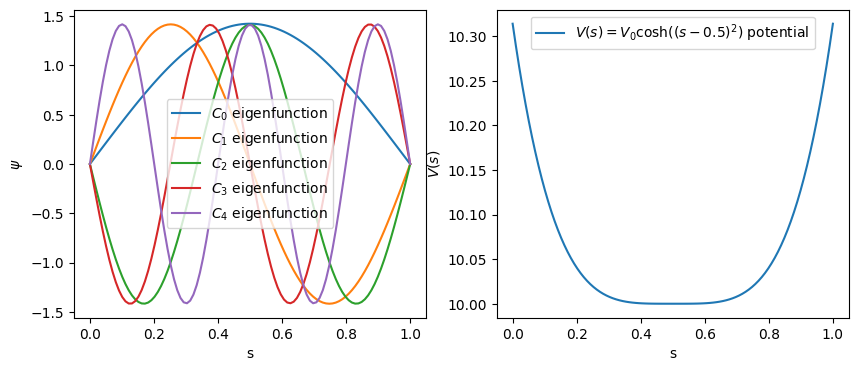

In [4]:
#HW 11 Part e
import numpy as np 
import matplotlib.pyplot as plt

#constants 
L = 1e-9 #unit: nm 

#orthornormality check on eigenvectors 
G = vec.T @ vec
print("eigenvectors: Orthornormality matrix (should be identity):\n", np.round(G, 5))

#s-array 
s = np.linspace(0,1,100) 


#basis states function definition 
def sin(N_basis, s): 
    basis = np.zeros((N_basis, N_basis), dtype = float) 
    for n in range(1, N_basis + 1): 
        basis[n-1, :] = np.sqrt(2.0)*np.sin(n*Pi*s)
    return basis
    
basis = sin(100, s)
psi =   basis.T @ vec

#psi orthogonality check
ds = s[1] - s[0] 
Ortho = (psi.T @ psi) * ds
print("wavefunctions: Orthornormality matrix (should be identity):\n", np.round(Ortho, 5))
    
#Accessing each eigenvector 
c0 = psi[:,0] 
c1 = psi[:,1] 
c2 = psi[:,2] 
c3 = psi[:,3] 
c4 = psi[:,4] 

#potential energy function 
def V(s):
    V = V_0*np.cosh((s - 0.5)**2)
    return V 

# arrangements for subplot 
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(s, c0, label = r"$C_{0}$ eigenfunction")
axes[0].plot(s, c1, label = r"$C_{1}$ eigenfunction")
axes[0].plot(s, c2, label = r"$C_{2}$ eigenfunction")
axes[0].plot(s, c3, label = r"$C_{3}$ eigenfunction")
axes[0].plot(s, c4, label = r"$C_{4}$ eigenfunction")
axes[0].set_xlabel(r"s")
axes[0].set_ylabel(r"$\psi$")
axes[0].legend(loc="best")
axes[1].plot(s, V(s), label = r"$V(s) = V_0 \cosh\!\left( (s - 0.5)^2 \right)$ potential")
axes[1].set_xlabel(r"s")
axes[1].set_ylabel("$V(s)$")
axes[1].legend(loc="best")




